In [5]:
from __future__ import annotations

from typing import Dict, List, Mapping, Tuple, Union
import numpy as np
import nibabel as nib
from nibabel.nifti1 import Nifti1Image
from nilearn.image import resample_to_img
from nilearn.masking import compute_epi_mask
from collections import defaultdict
from pathlib import Path
import re
import math
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from nilearn import plotting

In [6]:
CONTRAST_RE = re.compile(r"contrast-([^_/]+)")
SUB_RE = re.compile(r"(sub-[^_/]+)")

def build_study_roots(fitlins_deriv_out):
    """Return {ds_name: path} for every ds* folder in fitlins_deriv_out."""
    fitlins_deriv_out = Path(fitlins_deriv_out)
    return {
        p.name: p
        for p in sorted(fitlins_deriv_out.glob("ds*"))
        if p.is_dir()
    }


def list_contrasts(task_dir):
    """Sorted unique contrast names found in *stat-effect_* maps under a task folder."""
    found = set()
    for f in Path(task_dir).rglob("*stat-effect_*"):
        m = CONTRAST_RE.search(f.name)
        if m:
            found.add(m.group(1))
    return sorted(found)


def build_contrasts(study_roots, n=1):
    """
    For each study and each task-* folder, pick the n-th contrast (1-indexed).
    Returns {ds_name: {task_name: contrast}}.
    If a task has fewer than n contrasts, it is skipped with a warning.
    """
    if n < 1:
        raise ValueError("n must be >= 1 (1 = first contrast)")

    contrasts = {}
    for ds_name, root in study_roots.items():
        contrasts[ds_name] = {}
        for task_dir in sorted(Path(root).glob("task-*")):
            if not task_dir.is_dir():
                continue
            task = task_dir.name.removeprefix("task-")
            available = list_contrasts(task_dir)
            if len(available) >= n:
                contrasts[ds_name][task] = available[n - 1]
            else:
                print(f"[warn] {ds_name}/{task}: only {len(available)} contrast(s) found, "
                      f"cannot pick #{n}")
    return contrasts



def find_contrast_files(
    study_roots: Mapping[str, Union[str, Path]],
    contrasts: Mapping[str, Mapping[str, str]],
    stat: str = "effect",
    node: str = "node-subjectLevel",
) -> Dict[Tuple[str, str], List[str]]:
    """Find stat maps for a contrast specified per study and per task.

    Searches only ``<study_root>/task-<task>/<node>``, which avoids walking
    the whole study tree.

    Args:
        study_roots: Mapping ``{study_name: FitLins output directory}``.
        contrasts: Nested mapping ``{study_name: {task_label: contrast_label}}``.
        stat: Statistic label (value after ``stat-``), e.g. ``effect`` or ``t``.
        node: Name of the FitLins node directory holding the maps.

    Returns:
        Mapping ``{(study, task): sorted file paths}``. Pairs whose directory
        is missing or has no matching files are omitted.
    """
    groups: Dict[Tuple[str, str], List[str]] = {}
    for study, task_contrasts in contrasts.items():
        for task, contrast in task_contrasts.items():
            folder = Path(study_roots[study]) / f"task-{task}" / node
            files = sorted(
                str(f)
                for f in folder.rglob(f"*contrast-{contrast}_*stat-{stat}_*")
                if f.name.endswith((".nii", ".nii.gz"))
            )
            if files:
                groups[(study, task)] = files
    return groups
    
# overlap est
def statmap_mask(f) -> Nifti1Image:
    img = nib.load(f)
    data = np.asarray(img.dataobj)
    return nib.Nifti1Image((np.isfinite(data) & (data != 0)).astype(np.uint8),
                           img.affine)


def get_binary_masks(files, ref_img=None):
    imgs = [nib.load(f) for f in files]
    ref = ref_img if ref_img is not None else imgs[0]
    arrays = []
    
    for img in imgs:
        if img.shape != ref.shape:
            raise ValueError("Image dimensions do not match reference")

        if not np.allclose(img.affine, ref.affine, atol=1e-5):
            raise ValueError("Image affines do not match reference")

        data = np.asarray(img.dataobj)
        arrays.append(np.isfinite(data) & (data != 0))

    return arrays, ref


def compute_overlap(masks, ref_img):
    count = np.sum(masks, axis=0)
    percent = 100.0 * count / len(masks)
    return (
        nib.Nifti1Image(count.astype(np.int16), ref_img.affine),
        nib.Nifti1Image(percent.astype(np.float32), ref_img.affine),
    )


def overlap_summary(masks):
    stack = np.stack(masks)
    union = stack.any(axis=0).sum()
    inter = stack.all(axis=0).sum()
    mean_size = stack.sum(axis=(1, 2, 3)).mean()
    return {
        "n_masks": len(masks),
        "union_voxels": int(union),
        "intersection_voxels": int(inter),
        "pct_all_of_union": 100.0 * inter / union,
        "pct_all_of_mean_mask": 100.0 * inter / mean_size,
    }

def run_overlap(groups, out_dir, ref_img=None, collapse_sessions=True):
    """
    groups: {(ds, task): [files]}
    collapse_sessions: if True, combine multiple files per subject (e.g. ses-1,
        ses-2) into one subject-level mask (voxel kept only if present in ALL
        of that subject's files), so overlap is computed across subjects.
    """
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    rows = []

    for (ds, task), files in groups.items():
        if len(files) < 2:
            print(f"[warn] {ds}/{task}: {len(files)} file(s), skipping")
            continue

        masks, ref = get_binary_masks(files, ref_img=ref_img)

        if collapse_sessions:
            by_sub = defaultdict(list)
            for f, m in zip(files, masks):
                by_sub[SUB_RE.search(str(f)).group(1)].append(m)
            masks = [np.logical_and.reduce(ms) for ms in by_sub.values()]

        print(f"{ds}/{task}: {len(files)} files -> {len(masks)} masks")

        count_img, percent_img = compute_overlap(masks, ref)
        nib.save(percent_img, out_dir / f"{ds}_task-{task}_overlap-percent.nii.gz")
        nib.save(count_img,   out_dir / f"{ds}_task-{task}_overlap-count.nii.gz")

        rows.append({"study": ds, "task": task, **overlap_summary(masks)})

    return pd.DataFrame(rows)

## Overview, assumptions & how voxel overlap is calculated

This notebook asks: **how much of the MNI152 brain is covered by data, per study/task and across studies?** Coverage is computed from the subject-level maps (`node-subjectLevel`); all maps are assumed to be in the same standard space.

### Assumptions

**A1. One contrast per task is enough.** Coverage reflects each subject's brain mask / data availability, not the contrast being estimated: every contrast of a task is fit from the same preprocessed data and subject mask. We pick one contrast per task (`build_contrasts(..., n=1)`) and treat its coverage as representative of the task.
Caveats: (i) a subject lacking the conditions for the chosen contrast has no file and drops out, so *N* can differ slightly between contrasts; (ii) "has data" means finite and non-zero, so a voxel with an effect of exactly `0.0` counts as missing (negligible for float effect maps).

**A2. Group maps do not drop voxels that some subjects lack, so group-map extent is not used as a coverage measure.** FitLins ([`nistats.py`](https://github.com/poldracklab/fitlins/blob/dev/fitlins/interfaces/nistats.py#L385)) passes the subject effect maps to nilearn's `SecondLevelModel`, which builds a `NiftiMasker`. The group map then appears to keep voxels where some subjects are missing (missing subjects enter as zeros) instead of using the intersection. Supporting evidence: the ds000229 Dice table ([`ds000229_task-flavor_hist-dicesimilarity.tsv`](https://github.com/demidenm/openneuro_glmfitlins/blob/main/statsmodel_specs/ds000229/group_flavor/files/ds000229_task-flavor_hist-dicesimilarity.tsv)) shows sub-07 with ~67% of voxels in the MNI152 mask vs ~83-89% for other subjects, yet the group map is not restricted to sub-07's coverage. This is an assumption (not tested in this notebook); it is why coverage is computed from the subject maps directly.

**A3. Subjects are the unit.** Runs/sessions of one subject are collapsed into one subject mask (voxel kept only if present in *all* of that subject's files, `collapse_sessions=True`).

**A4. Everything is evaluated inside the MNI152 brain mask.** Voxels outside it are ignored. Stat maps are never resampled; if a study's grid differs from the 2 mm MNI152 mask, the *mask* is resampled (nearest neighbour) to the study's grid instead.

### How voxel overlap is calculated

For one study/task with *N* subjects, a `NiftiMasker` (mask = MNI152 brain mask) extracts each subject map as a vector of MNI voxels. Let `m_s(v) = 1` if subject *s* has a finite, non-zero value in voxel *v*, else 0.

| Quantity | Definition |
|---|---|
| Subject count | `count(v) = sum_s m_s(v)` |
| Subject percent | `pct(v) = 100 * count(v) / N` |
| Study mask | `M70(v) = 1` if `count(v) / N >= 0.70` (`THRESH`) |
| MNI coverage | `pct_mni_ge70 = 100 * sum(M70) / n_MNI_voxels`; likewise `pct_mni_all_subjects` for `count == N` |
| Subject coverage | per subject: % of MNI voxels with data, and % of `M70` voxels the subject has |

**Across studies**, each study/task contributes its `M70` mask on a common grid (MNI152 2 mm; resampled only if needed). With *K* masks: `across_count(v) = sum_k M70_k(v)`, `across_pct(v) = 100 * across_count(v) / K`. Pairwise agreement of masks A, B: `Dice = 2|A∩B| / (|A|+|B|)`, `Jaccard = |A∩B| / |A∪B|`.

Note: the threshold is `>=` 70% of subjects (e.g. 7 of 10). nilearn's `intersect_masks(threshold=0.7)` uses a strict `>`, and by default keeps only the largest connected component, so it would give slightly different masks.

## Setup

In [7]:
fitlins_deriv_out = Path('/oak/stanford/groups/russpold/data/OpenNeuro_analyses/openneuro_fitlins/analyses')

## Build Study roots _ Contrast List

In [8]:
study_roots = build_study_roots(fitlins_deriv_out)
contrasts = build_contrasts(study_roots, n=1)   

[warn] ds001734/MGTM2equalRange: only 0 contrast(s) found, cannot pick #1
[warn] ds001734/MGTM3equalIndifference: only 0 contrast(s) found, cannot pick #1
[warn] ds001734/MGTM3equalRange: only 0 contrast(s) found, cannot pick #1
[warn] ds002338/MIpost: only 0 contrast(s) found, cannot pick #1
[warn] ds002338/MIpre: only 0 contrast(s) found, cannot pick #1
[warn] ds003831/modulate2: only 0 contrast(s) found, cannot pick #1


In [9]:
groups = find_contrast_files(study_roots, contrasts)


In [10]:
df = run_overlap(groups, out_dir="overlap_vals") # collapse_sessions=True), otherwise set to False
df.to_csv("overlap_vals/overlap_summary.csv", index=False)

ds000001/balloonanalogrisktask: 16 files -> 16 masks
ds000002/deterministicclassification: 17 files -> 17 masks
ds000002/mixedeventrelatedprobe: 17 files -> 17 masks
ds000002/probabilisticclassification: 17 files -> 17 masks
ds000005/mixedgamblestask: 16 files -> 16 masks
ds000008/conditionalstopsignal: 13 files -> 13 masks
ds000008/stopsignal: 14 files -> 14 masks
ds000009/emotionalregulation: 24 files -> 24 masks
ds000009/stopsignal: 24 files -> 24 masks
ds000051/abstractconcretejudgment: 13 files -> 13 masks
ds000052/reversalweatherprediction: 13 files -> 13 masks
ds000052/weatherprediction: 13 files -> 13 masks
ds000102/flanker: 26 files -> 26 masks
ds000105/objectviewing: 6 files -> 6 masks
ds000108/Emotionregulation: 30 files -> 30 masks
ds000109/theoryofmindwithmanualresponse: 33 files -> 33 masks
ds000117/facerecognition: 16 files -> 16 masks
ds000120/antisaccadetaskwithfixedorder: 23 files -> 23 masks
ds000148/figure2backwith1backlures: 49 files -> 49 masks
ds000170/TrainedHan



In [70]:
out_dir  = Path("overlap_vals")
plot_dir = out_dir / "plots"
plot_dir.mkdir(parents=True, exist_ok=True)

keys = sorted(k for k in groups
              if (out_dir / f"{k[0]}_task-{k[1]}_overlap-percent.nii.gz").exists())

ROW_H = 2.0   # inches per row
fig, axes = plt.subplots(len(keys), 1, figsize=(10, ROW_H * len(keys)), squeeze=False)
fig.subplots_adjust(left=0.02, right=0.88, top=0.99, bottom=0.01, hspace=0.35)

for ax, (ds, task) in zip(axes[:, 0], keys):
    img = nib.load(out_dir / f"{ds}_task-{task}_overlap-percent.nii.gz")
    plotting.plot_stat_map(
        img, bg_img=None, display_mode="z", cut_coords=7,
        vmin=0, vmax=100, threshold=1e-6, cmap="viridis",
        colorbar=False, title=None, annotate=False, axes=ax,
    )
    ax.text(0.0, 1.02, f"{ds} / task-{task}", transform=ax.transAxes,
            ha="left", va="bottom", fontsize=10, fontweight="bold")

sm = mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(0, 100), cmap="viridis")
fig.colorbar(sm, cax=fig.add_axes([0.91, 0.97, 0.015, 0.02]), label="% of subjects")

fig.savefig(plot_dir / "all_overlap_maps.png", dpi=100)
plt.show()

## Study/task voxel coverage (>=70% of subjects) and overlap across datasets

Steps: (1) find the subject-level maps for the single contrast per task; (2) per study/task, extract subjects x MNI voxels with a `NiftiMasker`, count subjects per voxel and threshold at `THRESH`; (3) report the % of MNI152 voxels meeting the threshold; (4) overlap of the study masks across datasets. See *Assumptions* above.

In [15]:
from nilearn.datasets import load_mni152_brain_mask
from nilearn.maskers import NiftiMasker

THRESH = 0.70                      # min fraction of subjects with data in a voxel
SUBJ_NODE = "node-subjectLevel"

def same_grid(img, ref):
    return img.shape[:3] == ref.shape[:3] and np.allclose(img.affine, ref.affine, atol=1e-5)


def to_ref_grid(mask, affine, ref):
    """Nearest-neighbour resample a boolean mask onto ref (no-op if grids match)."""
    if mask.shape == ref.shape and np.allclose(affine, ref.affine, atol=1e-5):
        return mask
    out = resample_to_img(Nifti1Image(mask.astype(np.uint8), affine), ref,
                          interpolation="nearest", force_resample=True, copy_header=True)
    return np.asarray(out.dataobj) > 0


def subject_has_data(files, mni_mask, collapse_sessions=True):
    """Boolean (n_subjects x n_mni_voxels) 'has data' matrix for one study/task.

    A NiftiMasker restricted to the MNI152 brain mask pulls out one row of voxel
    values per file; 'has data' = finite and non-zero. With ``collapse_sessions``
    the rows of one subject (runs/sessions) are ANDed into a single row.
    Returns (matrix, subject_ids, masker).
    """
    masker = NiftiMasker(mask_img=mni_mask).fit()
    X = masker.transform(files) # (n_files, n_voxels)
    has_voxels = np.isfinite(X) & (X != 0)
    if not collapse_sessions:
        return has_voxels, [Path(f).name for f in files], masker

    by_sub = defaultdict(list)
    for i, f in enumerate(files):
        by_sub[SUB_RE.search(str(f)).group(1)].append(i)
    subs = list(by_sub)
    return np.stack([has_voxels[by_sub[s]].all(axis=0) for s in subs]), subs, masker


def run_study_coverage(groups, out_dir, thresh=THRESH, collapse_sessions=True,
                       mni_mask=None):
    """For every (study, task): per-voxel subject count and the >=thresh mask.

    All maps are assumed to share one standard space; the MNI152 brain mask is
    put on each study's grid once (nearest neighbour) if the grids differ, so
    stat maps themselves are never resampled.

    Saves {ds}_task-{task}_subjcount / _subjpercent / _mask-ge70 niftis.
    Returns (summary_df, subject_df, {(ds, task): >=thresh mask image}).
    """
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)
    mni = mni_mask if mni_mask is not None else load_mni152_brain_mask(resolution=2)
    tag = f"ge{int(thresh * 100)}"
    summ_rows, subj_rows, study_masks = [], [], {}

    for (ds, task), files in groups.items():
        if len(files) < 2:
            print(f"[warn] {ds}/{task}: {len(files)} file(s), skipping")
            continue

        ref = nib.load(files[0]) # get one to confirm ref match
        grid_mni = mni if same_grid(ref, mni) else resample_to_img(
            mni, ref, interpolation="nearest", force_resample=True, copy_header=True)
        n_mni = int(np.asarray(grid_mni.dataobj).astype(bool).sum())

        has_voxels, subs, masker = subject_has_data(files, grid_mni, collapse_sessions)
        n = has_voxels.shape[0]
        count = has_voxels.sum(axis=0)
        in_mask = count >= thresh * n - 1e-9            # >= thresh of subjects
        n_thr, n_all = int(in_mask.sum()), int((count == n).sum())
        print(f"{ds}/{task}: {n} subjects, {n_thr} / {n_mni} MNI voxels >= {thresh:.0%}")

        stem = out_dir / f"{ds}_task-{task}"
        nib.save(masker.inverse_transform(count.astype(np.int16)), f"{stem}_subjcount.nii.gz")
        nib.save(masker.inverse_transform((100.0 * count / n).astype(np.float32)),
                 f"{stem}_subjpercent.nii.gz")
        thr_img = masker.inverse_transform(in_mask.astype(np.uint8))
        nib.save(thr_img, f"{stem}_mask-{tag}.nii.gz")

        summ_rows.append({
            "study": ds, "task": task, "n_subjects": n, "n_mni_vox": n_mni,
            "n_vox_any": int((count > 0).sum()),
            f"n_vox_{tag}": n_thr, "n_vox_all_subjects": n_all,
            f"pct_mni_{tag}": 100.0 * n_thr / n_mni,
            "pct_mni_all_subjects": 100.0 * n_all / n_mni,
        })
        subj_rows += [{
            "study": ds, "task": task, "subject": s,
            "pct_mni_covered": 100.0 * row.sum() / n_mni,
            f"pct_{tag}_mask_covered": 100.0 * (row & in_mask).sum() / max(n_thr, 1),
        } for s, row in zip(subs, has_voxels)]
        study_masks[(ds, task)] = thr_img

    return pd.DataFrame(summ_rows), pd.DataFrame(subj_rows), study_masks


def cross_study_overlap(study_masks, out_dir, ref_img=None, tag="ge70"):
    """Overlap of per-study masks across datasets (common grid = MNI152 2mm by default).

    Returns (count_img, pct_img, per-study DataFrame, dice DataFrame, jaccard DataFrame).
    """
    ref = ref_img if ref_img is not None else load_mni152_brain_mask(resolution=2)
    keys = list(study_masks)
    names = [f"{ds}/{task}" for ds, task in keys]
    stack = np.stack([to_ref_grid(np.asarray(study_masks[k].dataobj) > 0,
                                  study_masks[k].affine, ref) for k in keys])

    count = stack.sum(axis=0)
    count_img = Nifti1Image(count.astype(np.int16), ref.affine)
    pct_img = Nifti1Image((100.0 * count / len(keys)).astype(np.float32), ref.affine)
    nib.save(count_img, Path(out_dir) / f"across_studies_{tag}_count.nii.gz")
    nib.save(pct_img, Path(out_dir) / f"across_studies_{tag}_percent.nii.gz")

    flat = stack.reshape(len(keys), -1)                  # pairwise similarity
    M = flat[:, flat.any(axis=0)].astype(np.float32)
    inter = M @ M.T
    size = np.diag(inter)
    tot = size[:, None] + size[None, :]
    with np.errstate(divide="ignore", invalid="ignore"):
        dice, jacc = 2 * inter / tot, inter / (tot - inter)

    brain = np.asarray(ref.dataobj) > 0
    per_study = pd.DataFrame({
        "study_task": names, "n_vox": size.astype(int),
        "pct_of_ref_brain": [100.0 * (s & brain).sum() / brain.sum() for s in stack],
        "n_vox_unique": [int((s & (count == 1)).sum()) for s in stack],
    })
    return (count_img, pct_img, per_study,
            pd.DataFrame(dice, index=names, columns=names),
            pd.DataFrame(jacc, index=names, columns=names))


In [16]:
from templateflow import api as tflow
#fmriprep, what fitlins runs are space-MNI152NLin2009cAsym_res-2_
mni152res2 = nib.load(tflow.get("MNI152NLin2009cAsym", resolution=2,
                         desc="brain", suffix="mask"))

subj_groups = find_contrast_files(study_roots, contrasts, node=SUBJ_NODE)

cov_dir = Path("overlap_vals/coverage")
cov_df, subj_df, study_masks = run_study_coverage(subj_groups, out_dir=cov_dir, thresh=THRESH, mni_mask=mni152res2)

cov_df.to_csv(cov_dir / "study_coverage_summary.csv", index=False)
subj_df.to_csv(cov_dir / "subject_coverage.csv", index=False)
cov_df.sort_values("pct_mni_ge70")

ds000001/balloonanalogrisktask: 16 subjects, 221911 / 235840 MNI voxels >= 70%
ds000002/deterministicclassification: 17 subjects, 223425 / 235840 MNI voxels >= 70%
ds000002/mixedeventrelatedprobe: 17 subjects, 224009 / 235840 MNI voxels >= 70%
ds000002/probabilisticclassification: 17 subjects, 223795 / 235840 MNI voxels >= 70%
ds000005/mixedgamblestask: 16 subjects, 220547 / 235840 MNI voxels >= 70%
ds000008/conditionalstopsignal: 13 subjects, 221416 / 235840 MNI voxels >= 70%
ds000008/stopsignal: 14 subjects, 222971 / 235840 MNI voxels >= 70%
ds000009/emotionalregulation: 24 subjects, 216324 / 235840 MNI voxels >= 70%
ds000009/stopsignal: 24 subjects, 215996 / 235840 MNI voxels >= 70%
ds000051/abstractconcretejudgment: 13 subjects, 220348 / 235840 MNI voxels >= 70%
ds000052/reversalweatherprediction: 13 subjects, 213648 / 235840 MNI voxels >= 70%
ds000052/weatherprediction: 13 subjects, 213705 / 235840 MNI voxels >= 70%
ds000102/flanker: 26 subjects, 226510 / 235840 MNI voxels >= 70%


,study,task,n_subjects,n_mni_vox,n_vox_any,n_vox_ge70,n_vox_all_subjects,pct_mni_ge70,pct_mni_all_subjects
45,ds002338,2dNF,8,235840,141777,112117,96202,47.539434,40.791214
44,ds002338,1dNF,9,235840,164501,113499,98260,48.125424,41.663840
46,ds002422,arithm,45,235840,203177,154512,103461,65.515604,43.869149
28,ds000255,viewFigure,2,235840,212391,192929,192929,81.805037,81.805037
29,ds000255,viewRandom,2,235840,212877,195055,195055,82.706496,82.706496
...,...,...,...,...,...,...,...,...,...
42,ds002033,ChangeDetection,40,235840,235765,232714,216869,98.674525,91.955987
43,ds002294,roletrait,40,235840,235774,232951,223926,98.775017,94.948270
36,ds001715,dts,34,235840,235790,233500,224768,99.007802,95.305292
27,ds000229,flavor,15,235840,235840,233638,226685,99.066316,96.118131


In [25]:
# compare to derive decide values, local clone on oak 
# https://github.com/demidenm/openneuro_glmfitlins/blob/main/statsmodel_specs
SPECS = Path("/oak/stanford/groups/russpold/users/demidenm/openneuro_glmfitlins/statsmodel_specs")   

def load_dice_tsv(ds, task, specs=SPECS):
    f = specs / ds / f"group_{task}" / "files" / f"{ds}_task-{task}_hist-dicesimilarity.tsv"
    if not f.exists():
        return None
    d = pd.read_csv(f, sep="\t")
    v = d["voxinmask"] / 100
    d["subject"] = d["img1"].str.extract(r"(sub-[^_]+)")[0]
    # collapse runs the same way as the notebook (voxel must be in ALL runs) -> use the minimum
    return (d.groupby("subject", as_index=False)
              .agg(dice_min=("dice", "min")))

tsv = pd.concat(
    [t.assign(study=ds, task=task)
     for (ds, task) in study_masks
     if (t := load_dice_tsv(ds, task)) is not None])

check = subj_df.merge(tsv, on=["study", "task", "subject"], how="left")


- n_mni_vox: Total number of voxels in the MNI152 brain mask, after aligning it to the study's grid.
- n_vox_any:Number of voxels with nonzero, finite data in at least one subject.
- n_vox_ge70: Number of voxels with nonzero, finite data in at least 70% of subjects.
- n_vox_all_subjects: Number of voxels with nonzero, finite data in every subject.
- pct_mni_ge70: Percentage of all MNI152 brain-mask voxels covered by at least 70% of subjects.
- pct_mni_all_subjects: Percentage of all MNI152 brain-mask voxels covered by every subject.

In [24]:
# subjects with the lowest coverage of their study's 70% mask
check.sort_values("pct_mni_covered", key=abs, ascending=True).head(15)

,study,task,subject,pct_mni_covered,pct_ge70_mask_covered,dice_min
1095,ds002338,2dNF,sub-xp210,42.051815,88.223017,0.568997
1083,ds002338,1dNF,sub-xp201,46.703697,92.954123,0.500446
1099,ds002338,2dNF,sub-xp221,46.815638,97.164569,0.607779
1089,ds002338,1dNF,sub-xp219,48.448948,96.233447,0.610645
1481,ds003545,prodL1,sub-21,48.571913,54.257778,0.673160
1087,ds002338,1dNF,sub-xp211,49.160024,99.623785,0.615628
1098,ds002338,2dNF,sub-xp217,49.949118,99.662852,0.619564
1094,ds002338,2dNF,sub-xp207,49.983463,97.831729,0.504841
1092,ds002338,2dNF,sub-xp204,50.167062,99.106291,0.621873
1084,ds002338,1dNF,sub-xp202,50.303172,97.171781,0.626757


In [ ]:
# example study/task: % of subjects with data, and the >=70% mask
ds, task = next(iter(study_masks))        # change to any key of study_masks
stem = cov_dir / f"{ds}_task-{task}"
panels = [("% subjects with data", f"{stem}_subjpercent.nii.gz", 100),
          (">=70% mask", f"{stem}_mask-ge70.nii.gz", 1)]
fig, axes = plt.subplots(len(panels), 1, figsize=(10, 2.2 * len(panels)))
for ax, (title, path, vmax) in zip(axes, panels):
    plotting.plot_stat_map(nib.load(path), display_mode="z", cut_coords=7, vmin=0, vmax=vmax,
                           threshold=1e-6, cmap="viridis", colorbar=True, annotate=False,
                           title=f"{ds}/{task}: {title}", axes=ax)
plt.show()

### Overlap across datasets

Each study/task's `M70` mask is stacked on a common grid. `across_percent` = % of study/tasks whose 70% mask contains the voxel. `per_study.n_vox_unique` counts voxels covered by that study only.

In [28]:
count_img, pct_img, per_study, dice, jaccard = cross_study_overlap(
    study_masks, out_dir=cov_dir, tag=f"ge{int(THRESH*100)}")

K = len(study_masks)
across = np.asarray(pct_img.dataobj)
print(f"{K} study/tasks")

per_study.to_csv(cov_dir / "across_studies_per_study.csv", index=False)
dice.to_csv(cov_dir / "across_studies_dice.csv")
per_study.sort_values("pct_of_ref_brain").head(10)

68 study/tasks


,study_task,n_vox,pct_of_ref_brain,n_vox_unique
45,ds002338/2dNF,112117,47.321083,0
44,ds002338/1dNF,113499,47.918428,0
46,ds002422/arithm,154512,65.122889,0
28,ds000255/viewFigure,192929,81.304302,1
29,ds000255/viewRandom,195055,82.218163,0
50,ds003425/prelearning,200413,84.886245,0
52,ds003425/training,200862,85.078704,0
49,ds003425/learning,201788,85.459373,0
58,ds003545/compL1,206990,87.594689,0
26,ds000212/fb,208327,87.853425,0


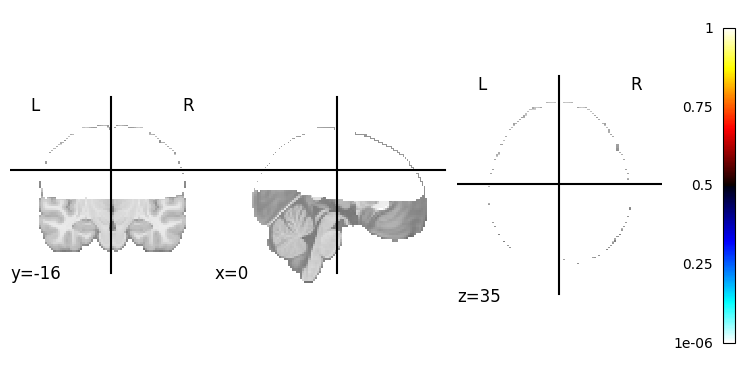

In [47]:
# consistent est
# https://github.com/demidenm/openneuro_glmfitlins/tree/main/statsmodel_specs/ds002338/group_1dNF#441-voxelwise-average-mean
plotting.plot_stat_map(study_masks['ds002338','1dNF'])

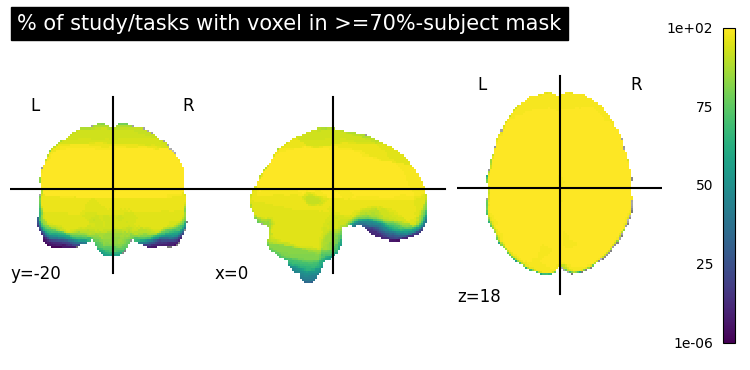

In [45]:
plotting.plot_stat_map(pct_img, display_mode="ortho", vmin=0, vmax=100,
                       threshold=1e-6, cmap="viridis", colorbar=True,
                       title=f"% of study/tasks with voxel in >={THRESH:.0%}-subject mask")

